# Isotherm fitting with the engine's isotherms

The package exposes the engine's isotherm code (`evaluate_isotherm`) and the engine's isotherm fitter (`fit_isotherm`, adsim/solver/isotherm_fit.h). Because both use the same isotherm functions as the simulator, fitted parameters can go straight into a deck.

**Data.** Schell et al. (2012) report per-temperature Sips fits for CO₂ on activated carbon AP3-60 between 25 and 140 °C (Table 3: $n_\infty$ [mol/kg], $k$ [1/MPa], $c$ [-], for the form $q = n_\infty (kp)^c / (1 + (kp)^c)$). The values below are as transcribed in this repository's Casas/Schell validation case (`adsim/test/papers/casas_2012/README.md`). The points fitted here are regenerated from those published fits at 0.5–40 bar; they are not the paper's raw measurements.

> Schell, J., Casas, N., Pini, R., Mazzotti, M. *Pure and binary adsorption of CO₂, H₂, and N₂ on activated carbon.* Adsorption 18(1):49–65 (2012). doi:10.1007/s10450-011-9382-y

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skarstrom

plt.rcParams["figure.dpi"] = 80
print("skarstrom", skarstrom.__version__)

skarstrom 0.1.0


In [2]:
# Schell et al. 2012, Table 3 (CO2): T [degC], n_inf [mol/kg], k [1/MPa], c [-]
table3 = pd.DataFrame(
    [(25, 13.27, 0.666, 0.74), (45, 12.11, 0.488, 0.77), (65, 9.85, 0.498, 0.88),
     (100, 8.38, 0.340, 0.93), (140, 7.22, 0.225, 0.94)],
    columns=["T_C", "n_inf", "k_per_MPa", "c"])

p = np.linspace(0.5e5, 40e5, 25)                 # Pa
rows = []
for r in table3.itertuples():
    z = (r.k_per_MPa * 1e-6 * p) ** r.c
    for pi, qi in zip(p, r.n_inf * z / (1 + z)):
        rows.append((pi, qi, r.T_C + 273.15))
data = pd.DataFrame(rows, columns=["p_Pa", "q_molkg", "T_K"])
data.groupby("T_K").size()

T_K
298.15    25
318.15    25
338.15    25
373.15    25
413.15    25
dtype: int64

## 1. One temperature, the engine's fitter

The engine's `sips` isotherm is $q = q_{sat} z/(1+z)$ with $z = (b\,p)^{1/v}$, so it should recover $q_{sat} = n_\infty$, $b = k$ and $v = 1/c$ from the 25 °C curve.

In [3]:
print(skarstrom.isotherm_parameters("sips"))
d25 = data[data.T_K == 298.15]
fit = skarstrom.fit_isotherm("sips", d25.p_Pa, d25.q_molkg, temperature=298.15)
row = table3.iloc[0]
pd.DataFrame({
    "fitted": [fit["params"]["q_sat"], fit["params"]["b"], fit["params"]["v"]],
    "std error": [fit["std_errors"]["q_sat"], fit["std_errors"]["b"], fit["std_errors"]["v"]],
    "Table 3": [row.n_inf, row.k_per_MPa * 1e-6, 1 / row.c],
}, index=["q_sat [mol/kg]", "b [1/Pa]", "v [-]"])

['q_sat', 'b', 'v']


,fitted,std error,Table 3
q_sat [mol/kg],1.327000e+01,6.265639e-15,1.327000e+01
b [1/Pa],6.660000e-07,9.142505e-22,6.660000e-07
v [-],1.351351e+00,6.201118e-16,1.351351e+00


## 2. The same fit with SciPy on engine-evaluated isotherms

`evaluate_isotherm` can serve as the model function of any optimiser. Here `scipy.optimize.curve_fit` fits the same three parameters; the two fits should agree.

In [4]:
from scipy.optimize import curve_fit

def model(p_pa, q_sat, log10_b, v):
    return skarstrom.evaluate_isotherm("sips", {"q_sat": q_sat, "b": 10 ** log10_b, "v": v}, p_pa, 298.15)

popt, pcov = curve_fit(model, d25.p_Pa.to_numpy(), d25.q_molkg.to_numpy(), p0=[10.0, -6.0, 1.0])
print("scipy : q_sat=%.4f  b=%.4e  v=%.4f" % (popt[0], 10 ** popt[1], popt[2]))
print("engine: q_sat=%.4f  b=%.4e  v=%.4f" % (fit["params"]["q_sat"], fit["params"]["b"], fit["params"]["v"]))

scipy : q_sat=13.2700  b=6.6600e-07  v=1.3514
engine: q_sat=13.2700  b=6.6600e-07  v=1.3514


## 3. All temperatures, one temperature-dependent model

A single temperature-dependent isotherm across all five temperatures. `toth_2` is one of the temperature-dependent kinds the fitter supports; the fit reports R², RMSE and standard errors.

In [5]:
kinds = skarstrom.isotherm_kinds()
print(kinds)
kind = "toth_2"
print(kind, skarstrom.isotherm_parameters(kind))
fitT = skarstrom.fit_isotherm(kind, data.p_Pa, data.q_molkg, temperature=data.T_K)
print("R2 = %.5f, RMSE = %.4f mol/kg, n = %d, dof = %d" % (fitT["r2"], fitT["rmse"], fitT["n"], fitT["dof"]))
pd.DataFrame({"value": fitT["params"], "std error": fitT["std_errors"]})

['henry', 'single_site_langmuir_p', 'dual_site_langmuir_p', 'single_site_langmuir_c', 'dual_site_langmuir_c', 'extended_single_site_langmuir_p', 'extended_dual_site_langmuir_p', 'freundlich', 'sips', 'dual_site_sips', 'toth', 'sips_2', 'extended_sips_2', 'toth_2']
toth_2 ['q_sat', 'x', 'T_0', 'b0', 'dH0', 'w0', 'alpha']
R2 = 0.99983, RMSE = 0.0302 mol/kg, n = 125, dof = 119


,value,std error
q_sat,1.351674e+01,3.290852e-01
x,4.793560e-01,1.201118e-01
T_0,3.481500e+02,NaN
b0,5.884849e-07,7.673640e-09
dH0,1.869038e+04,4.106040e+02
w0,5.783160e-01,1.136459e-02
alpha,-1.196419e-02,3.917325e-02


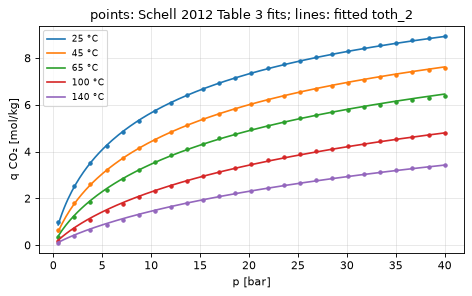

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
pp = np.linspace(0.5e5, 40e5, 200)
for T, g in data.groupby("T_K"):
    line, = ax.plot(g.p_Pa / 1e5, g.q_molkg, "o", ms=3)
    q = skarstrom.evaluate_isotherm(kind, fitT["params"], pp, T)
    ax.plot(pp / 1e5, q, "-", color=line.get_color(), label=f"{T - 273.15:.0f} °C")
ax.set_xlabel("p [bar]"); ax.set_ylabel("q CO₂ [mol/kg]")
ax.set_title(f"points: Schell 2012 Table 3 fits; lines: fitted {kind}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()

The fitted parameters use the deck's SI units, so they can be written into an adsorbent of a deck, `sim.adsorbents["13X"].isotherm["CO2"].<name> = value`, when that adsorbent uses the same isotherm kind.